# 6.0 - Pipeline final e sistema de recomendacao

## Decisoes finais (`config.py`)

| Cabeca | Previsor | Por que |
|---|---|---|
| 15, 30, 60 min | `persistencia` (score da camera agora) | nenhum modelo venceu a persistencia de forma significativa (3.0 e 5.0) |
| 90, 120 min | `base_estado` (LightGBM) | com folhas de ~1 dia, o LightGBM venceu a persistencia no CV e no hold out (5.0) |
| 180, 240, 360 min | `base_estado` (LightGBM) | o modelo vence a persistencia com folga (3.0 e 5.0) |

`MODELO_ATUAL` = tags + calendario + estado da camera: nenhum grupo de features novo melhorou (4.0).

## Fluxo

```
data/raw (Excel) --dataset.py--> data/interim --features.py--> data/processed --train.py--> models/modelo_y_<k>.pkl
                                                                      predict.py   --> probabilidade de pluma por cabeca
                                                                      recommend.py --> ajustes nas tags que baixam o risco
```

No terminal: `pluma tudo` (ou `make pipeline`). No Python: `from ml_atmospheric_emission.pipeline import treinar, prever, recomendar`.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ml_atmospheric_emission.config import (PATH_REPORTS, CABECAS_POSSIVEIS, PREVISOR_POR_CABECA, MODELOS, MODELO_ATUAL,
                                            VARIAVEIS_CONTROLE, ALGORITMO)
from ml_atmospheric_emission.dataset import load_interim
from ml_atmospheric_emission.features import create_training_dataset
from ml_atmospheric_emission.modeling.train import train_head_models
from ml_atmospheric_emission.modeling.evaluate import split_holdout, average_precision
from ml_atmospheric_emission.modeling.recommend import recommend_now, print_recommendation, predict_risk, validate_recommendations
from ml_atmospheric_emission.pipeline import treinar, prever, recomendar
from ml_atmospheric_emission.plots import plot_forecasts

## 1. Treino de todo o pipeline (o mesmo que `pluma treinar`)

Usa TODOS os dados (treino + hold out): a avaliacao ja foi feita nos notebooks 3.0 a 5.0.

In [3]:
treinar()

Interim salvo em /tmp/claude-0/-home-claude/22bcba14-99e8-5e72-856a-2b90ddb97672/scratchpad/v6/data/interim/dataset_interim.csv | linhas: 15074


Processed salvo em /tmp/claude-0/-home-claude/22bcba14-99e8-5e72-856a-2b90ddb97672/scratchpad/v6/data/processed/dataset_processed.csv | linhas: 14498 | colunas: 25


15 min: persistencia, nada para treinar
30 min: persistencia, nada para treinar
60 min: persistencia, nada para treinar
90 min: base_estado (lightgbm) | modelo salvo: modelo_y_90.pkl | linhas: 14361
120 min: base_estado (lightgbm) | modelo salvo: modelo_y_120.pkl | linhas: 14337
180 min: base_estado (lightgbm) | modelo salvo: modelo_y_180.pkl | linhas: 14292
240 min: base_estado (lightgbm) | modelo salvo: modelo_y_240.pkl | linhas: 14244
360 min: base_estado (lightgbm) | modelo salvo: modelo_y_360.pkl | linhas: 14148


## 2. Previsao em dias que o modelo nunca viu (hold out)

Para avaliar sem enganar, aqui os modelos das cabecas sao treinados SO no periodo de treino (nao sao salvos)
e preveem o hold out. Persistencia nas cabecas de 15 a 60 min, LightGBM nas outras.

In [4]:
ds = create_training_dataset(load_interim(), CABECAS_POSSIVEIS)
dx_treino, dx_holdout = split_holdout(ds)

modelos_treino = train_head_models(dx_treino, PREVISOR_POR_CABECA, MODELOS)
previsoes = dx_holdout[['Data']].copy()
for minutos in CABECAS_POSSIVEIS:
    if PREVISOR_POR_CABECA[minutos] == 'persistencia':
        previsoes['prob_' + str(minutos)] = dx_holdout['y'].values
    else:
        previsoes['prob_' + str(minutos)] = modelos_treino[minutos].predict_proba(dx_holdout[MODELO_ATUAL])[:, 1]

#AP of the final system in the hold out, next to the persistence in all heads
linhas = []
for minutos in CABECAS_POSSIVEIS:
    ok = dx_holdout['y_' + str(minutos)].notna().values
    classe = (dx_holdout['y_' + str(minutos)].values[ok] >= 0.5).astype(int)
    linhas.append({
        'minutos': minutos,
        'previsor': PREVISOR_POR_CABECA[minutos],
        'prevalencia': classe.mean(),
        'ap_sistema_final': average_precision(classe, previsoes['prob_' + str(minutos)].values[ok]),
        'ap_so_persistencia': average_precision(classe, dx_holdout['y'].values[ok])
    })
tabela_holdout = pd.DataFrame(linhas)
tabela_holdout.round(3)

Treino ate: 2026-10-02 23:15:00 | linhas treino: 11598 | linhas hold out: 2900


,minutos,previsor,prevalencia,ap_sistema_final,ap_so_persistencia
0,15,persistencia,0.123,0.721,0.721
1,30,persistencia,0.124,0.632,0.632
2,60,persistencia,0.124,0.471,0.471
3,90,base_estado,0.125,0.513,0.368
4,120,base_estado,0.125,0.469,0.323
5,180,base_estado,0.126,0.454,0.266
6,240,base_estado,0.126,0.411,0.240
7,360,base_estado,0.128,0.506,0.164


Dia com mais pluma no hold out: 2026-10-11


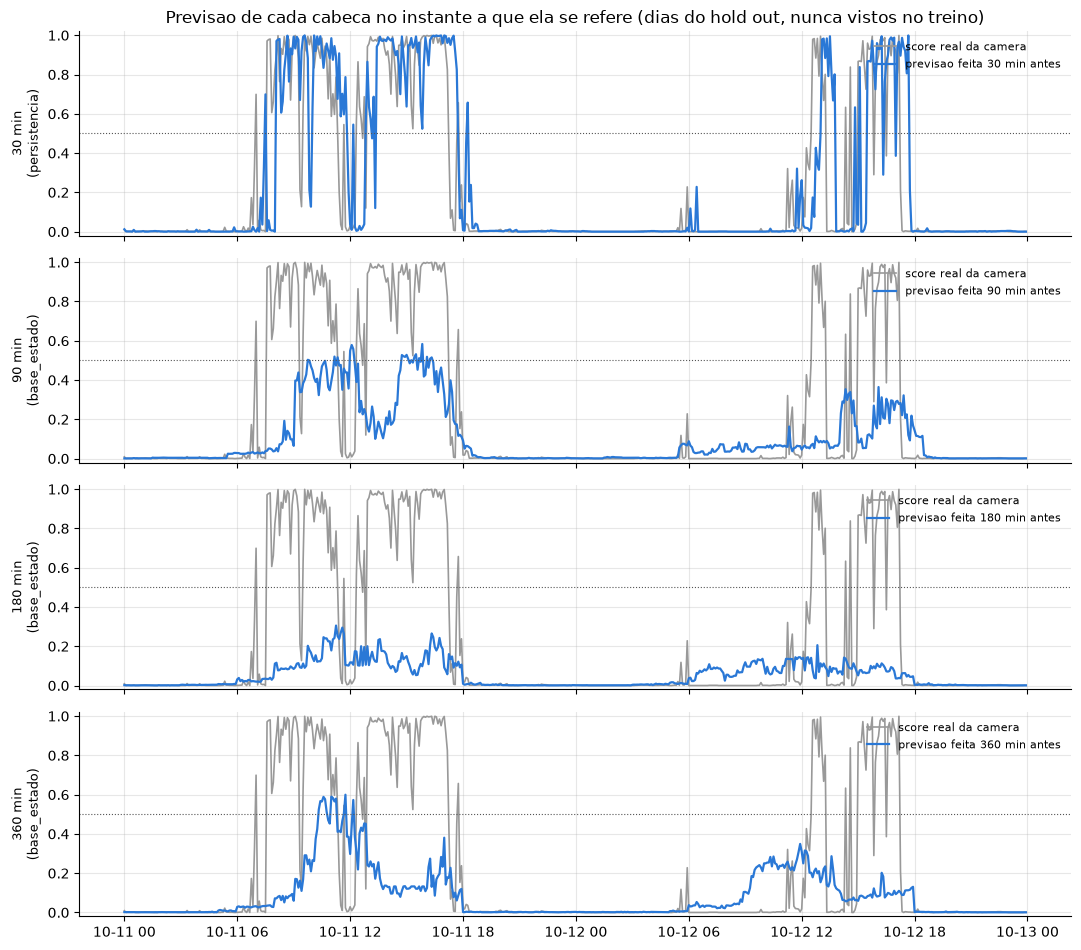

In [5]:
#The 2 days of the hold out with more plume hours
dia = (dx_holdout['y'] >= 0.5).groupby(dx_holdout['Data'].dt.date).sum().idxmax()
print('Dia com mais pluma no hold out:', dia)
plot_forecasts(dx_holdout, previsoes, PREVISOR_POR_CABECA, [30, 90, 180, 360], dia, 2, PATH_REPORTS / 'figures/previsao_holdout.png')

## 3. Recomendacao: exemplos nos momentos de maior risco do hold out

Risco = media da probabilidade de pluma das cabecas com modelo (90 a 360 min): as tags so entram nelas
(nas cabecas de persistencia a previsao e o score agora, mudar a tag nao mexe nela).
Regras: so as tags de `VARIAVEIS_CONTROLE` mudam, no maximo meio desvio padrao, dentro da faixa que a planta ja operou
(percentis 5 a 95 do treino) e com uma combinacao de tags parecida com a historia (distancia de Mahalanobis).

In [6]:
lista_modelos = []
for minutos in modelos_treino:
    lista_modelos.append(modelos_treino[minutos])
risco = predict_risk(lista_modelos, dx_holdout[MODELO_ATUAL])
for i in np.argsort(-risco)[:3]:
    momento = dx_holdout['Data'].iloc[i]
    #recommend_now recommends for the LAST row: the hold out up to the moment
    recomendacao = recommend_now(dx_treino, dx_holdout[dx_holdout['Data'] <= momento], modelos_treino, MODELO_ATUAL, VARIAVEIS_CONTROLE)
    print_recommendation(recomendacao['Data'], recomendacao)

Momento: 2026-10-09 09:45:00
Risco de pluma previsto agora: 0.595
Risco com a recomendacao: 0.422
  baixar 306-AIT-004-2 de 62.912 para 46.606
  subir 306-AIT-004-5 de 169.562 para 178.584
  baixar 306FE002-AI001-R de 3.409 para 1.792
  subir 406-AI-004-2 de 40.453 para 48.781
  baixar 406-AI-004-4 de 160.168 para 123.105
  baixar 406-AIT-001 de 1.722 para 1.481
Risco de cada cabeca (agora -> com a recomendacao):
    90 min: 0.722 -> 0.583
    120 min: 0.727 -> 0.534
    180 min: 0.617 -> 0.301
    240 min: 0.56 -> 0.484
    360 min: 0.347 -> 0.209
ATENCAO: recomendacao NAO validada (notebook 6.0). E uma hipotese para testar com a operacao, nao uma ordem

Momento: 2026-10-09 09:50:00
Risco de pluma previsto agora: 0.563
Risco com a recomendacao: 0.394
  baixar 306-AIT-004-2 de 60.723 para 44.417
  subir 306-AIT-004-5 de 168.165 para 177.187
  subir 306FE002-AI001-R de 5.245 para 8.878
  subir 406-AI-004-2 de 35.55 para 49.225
  baixar 406-AI-004-4 de 171.575 para 149.337
  baixar 406-A

Momento: 2026-10-09 12:30:00
Risco de pluma previsto agora: 0.452
Risco com a recomendacao: 0.346
  subir 306-AIT-004-2 de 67.731 para 80.776
  subir 306-AIT-004-5 de 202.361 para 238.45
  subir 306FE002-AI001-R de 13.646 para 15.082
  subir 406-AI-004-2 de 60.098 para 74.901
  subir 406-AI-004-4 de 191.477 para 228.54
  baixar 406-AIT-001 de 1.022 para 0.7
Risco de cada cabeca (agora -> com a recomendacao):
    90 min: 0.641 -> 0.476
    120 min: 0.662 -> 0.662
    180 min: 0.441 -> 0.334
    240 min: 0.514 -> 0.259
    360 min: 0.002 -> 0.001
ATENCAO: recomendacao NAO validada (notebook 6.0). E uma hipotese para testar com a operacao, nao uma ordem



## 4. A recomendacao se sustenta em outro periodo? (validacao)

O treino e dividido em duas metades (com 6 horas de intervalo). Cada metade treina os modelos das cabecas.
Os modelos de um periodo recomendam nos momentos de maior risco do seu periodo; os modelos do OUTRO periodo
(que nunca viram esses momentos) conferem. Controle: fazer o contrario (mesma mudanca, sentido oposto).
Se a recomendacao for real: o outro periodo tambem ve o risco cair, e fazer o contrario nao ajuda.

In [7]:
dr = dx_treino.sort_values('Data').reset_index(drop=True)
meio = len(dr) // 2
periodo_1 = dr.iloc[:meio - 72].reset_index(drop=True)   #72 x 5 min = 6 h of gap (the longest head)
periodo_2 = dr.iloc[meio:].reset_index(drop=True)
print('Periodo 1:', periodo_1['Data'].min(), 'ate', periodo_1['Data'].max())
print('Periodo 2:', periodo_2['Data'].min(), 'ate', periodo_2['Data'].max())

modelos_1 = []
modelos_periodo_1 = train_head_models(periodo_1, PREVISOR_POR_CABECA, MODELOS)
for minutos in modelos_periodo_1:
    modelos_1.append(modelos_periodo_1[minutos])
modelos_2 = []
modelos_periodo_2 = train_head_models(periodo_2, PREVISOR_POR_CABECA, MODELOS)
for minutos in modelos_periodo_2:
    modelos_2.append(modelos_periodo_2[minutos])

Periodo 1: 2026-08-20 14:15:00 ate 2026-09-10 09:45:00
Periodo 2: 2026-09-10 15:55:00 ate 2026-10-02 23:10:00


In [8]:
print('Recomenda: modelos do periodo 1 | Confere: modelos do periodo 2')
tabela_1, direcoes_1 = validate_recommendations(modelos_1, modelos_2, periodo_1, MODELO_ATUAL, VARIAVEIS_CONTROLE)
print('Recomenda: modelos do periodo 2 | Confere: modelos do periodo 1')
tabela_2, direcoes_2 = validate_recommendations(modelos_2, modelos_1, periodo_2, MODELO_ATUAL, VARIAVEIS_CONTROLE)

Recomenda: modelos do periodo 1 | Confere: modelos do periodo 2


Momentos avaliados: 150
Reducao de risco segundo o modelo que recomendou: 0.166
Reducao de risco segundo o modelo do outro periodo: -0.003
Reducao fazendo o contrario (outro periodo): 0.009
Outro periodo concorda que o risco cai: 47 %
Recomendacao melhor que fazer o contrario: 43 %
Direcoes recomendadas:
406-AI-004-2 subir         108
306FE002-AI001-R baixar    105
406-AIT-001 baixar         102
306-AIT-004-5 subir         88
406-AI-004-4 subir          78
306-AIT-004-2 baixar        73
306-AIT-004-2 subir         67
406-AI-004-4 baixar         62
306-AIT-004-5 baixar        38
306FE002-AI001-R subir      33
406-AIT-001 subir           27
406-AI-004-2 baixar         21

Recomenda: modelos do periodo 2 | Confere: modelos do periodo 1


Momentos avaliados: 150
Reducao de risco segundo o modelo que recomendou: 0.192
Reducao de risco segundo o modelo do outro periodo: -0.01
Reducao fazendo o contrario (outro periodo): 0.045
Outro periodo concorda que o risco cai: 42 %
Recomendacao melhor que fazer o contrario: 29 %
Direcoes recomendadas:
306FE002-AI001-R subir     139
406-AI-004-4 baixar        118
306-AIT-004-5 subir        106
406-AIT-001 baixar          99
406-AI-004-2 subir          87
306-AIT-004-2 subir         75
306-AIT-004-2 baixar        52
406-AI-004-2 baixar         52
406-AIT-001 subir           40
306-AIT-004-5 baixar        37
406-AI-004-4 subir          27
306FE002-AI001-R baixar      2



In [9]:
#Same direction in the two periods? A tag recommended 'subir' in one and 'baixar' in the other is not stable
ds_direcoes = pd.DataFrame({'periodo_1': direcoes_1, 'periodo_2': direcoes_2}).fillna(0).astype(int)
ds_direcoes.sort_index()

,periodo_1,periodo_2
306-AIT-004-2 baixar,73,52
306-AIT-004-2 subir,67,75
306-AIT-004-5 baixar,38,37
306-AIT-004-5 subir,88,106
306FE002-AI001-R baixar,105,2
306FE002-AI001-R subir,33,139
406-AI-004-2 baixar,21,52
406-AI-004-2 subir,108,87
406-AI-004-4 baixar,62,118
406-AI-004-4 subir,78,27


In [10]:
#Summary of the validation
linhas = []
for nome, tabela in [('recomenda 1, confere 2', tabela_1), ('recomenda 2, confere 1', tabela_2)]:
    reducao_val = tabela['risco_val_antes'] - tabela['risco_val_depois']
    reducao_contraria = tabela['risco_val_antes'] - tabela['risco_val_contrario']
    linhas.append({
        'validacao': nome,
        'momentos': len(tabela),
        'reducao_modelo_que_recomendou': (tabela['risco_rec_antes'] - tabela['risco_rec_depois']).mean(),
        'reducao_outro_periodo': reducao_val.mean(),
        'reducao_fazendo_o_contrario': reducao_contraria.mean(),
        'pct_outro_periodo_concorda': 100*(reducao_val > 0).mean(),
        'pct_melhor_que_o_contrario': 100*(reducao_val > reducao_contraria).mean()
    })
tabela_validacao = pd.DataFrame(linhas)
tabela_validacao.to_csv(PATH_REPORTS / 'validacao_recomendacao.csv', index=False)
tabela_validacao.round(3)

,validacao,momentos,reducao_modelo_que_recomendou,reducao_outro_periodo,reducao_fazendo_o_contrario,pct_outro_periodo_concorda,pct_melhor_que_o_contrario
0,"recomenda 1, confere 2",150,0.166,-0.003,0.009,47.333,43.333
1,"recomenda 2, confere 1",150,0.192,-0.010,0.045,42.000,28.667


### Conclusao da validacao

- O modelo que recomenda sempre ve o risco cair (ele escolhe a mudanca olhando para si mesmo).
- O modelo do OUTRO periodo concorda em ~45% dos momentos (cara ou coroa) e fazer o CONTRARIO ajuda tanto quanto.
- A direcao recomendada de algumas tags se inverte entre os periodos (ex.: `306FE002-AI001-R`).

Ou seja: a recomendacao **nao se sustenta**. O modelo usa as tags para prever (associacao), mas o efeito de MUDAR uma
tag nao e estavel. Isso combina com o notebook 2.0 (ganho das tags nao significativo no teste de permutacao).
Por isso `RECOMENDACAO_VALIDADA = False` no config: o sistema mostra a recomendacao com um aviso, como hipotese
para testar com a operacao (testes planejados na planta, mudando uma tag por vez), nao como ordem.

## 5. Usando como modulo (o que qualquer pessoa faz)

`prever(ds)` e `recomendar(ds)` recebem uma tabela de 5 em 5 minutos com `Data`, `nn_score_smog` e as tags
(pelo menos os ultimos 30 minutos). Aqui: as ultimas 2 horas do interim, com os modelos salvos pelo `treinar()`.

In [11]:
ds_novo = load_interim().sort_values('Data').tail(24)   #24 x 5 min = 2 horas
previsoes_novas = prever(ds_novo)
print(previsoes_novas.tail(3).set_index('Data').round(3).to_string())
print()
recomendacao = recomendar(ds_novo)
print_recommendation(recomendacao['Data'], recomendacao)

                     prob_15  prob_30  prob_60  prob_90  prob_120  prob_180  prob_240  prob_360
Data                                                                                           
2026-10-13 08:20:00    0.001    0.001    0.001    0.066     0.101     0.123     0.107     0.174
2026-10-13 08:25:00    0.001    0.001    0.001    0.062     0.098     0.102     0.101     0.150
2026-10-13 08:30:00    0.001    0.001    0.001    0.067     0.105     0.115     0.083     0.127



Momento: 2026-10-13 08:30:00
Risco de pluma previsto agora: 0.099
Risco com a recomendacao: 0.081
  baixar 306-AIT-004-2 de 58.262 para 41.818
  baixar 306-AIT-004-5 de 151.768 para 111.582
  baixar 306FE002-AI001-R de 2.98 para 1.321
  subir 406-AI-004-2 de 77.783 para 90.676
Risco de cada cabeca (agora -> com a recomendacao):
    90 min: 0.067 -> 0.064
    120 min: 0.105 -> 0.094
    180 min: 0.115 -> 0.09
    240 min: 0.083 -> 0.066
    360 min: 0.127 -> 0.089
ATENCAO: recomendacao NAO validada (notebook 6.0). E uma hipotese para testar com a operacao, nao uma ordem

